# Bài 7 — Nhận dạng chữ số viết tay với 2 ảnh kiểm thử

**Sinh viên:** Nguyễn Đức Vinh — **MSSV:** 6451071087

Huấn luyện cây quyết định trên `sklearn.datasets.load_digits` (1.797 ảnh 8×8); kiểm thử thêm **2 ảnh khác nhau** giảng viên cung cấp

- `test_image_Bai7_01.jpg`: ảnh chữ số 2 (theo quan sát bằng mắt).
- `test_image_Bai7_02.jpg`: ảnh chữ số 1 (theo quan sát bằng mắt).




Họ tên: Nguyễn Đức Vinh | MSSV: 6451071087
Dữ liệu sklearn digits (8x8): (1797, 64) Nhãn: [0 1 2 3 4 5 6 7 8 9]


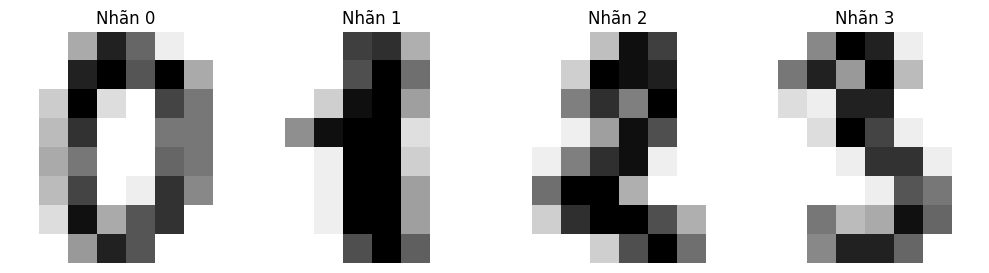

Accuracy của cây ID3 theo entropy: 0.8389
              precision    recall  f1-score   support

           0       1.00      0.89      0.94        36
           1       0.76      0.78      0.77        36
           2       0.88      0.86      0.87        35
           3       0.86      0.86      0.86        37
           4       0.87      0.92      0.89        36
           5       0.84      0.86      0.85        37
           6       0.74      0.89      0.81        36
           7       0.88      0.81      0.84        36
           8       0.78      0.71      0.75        35
           9       0.81      0.81      0.81        36

    accuracy                           0.84       360
   macro avg       0.84      0.84      0.84       360
weighted avg       0.84      0.84      0.84       360



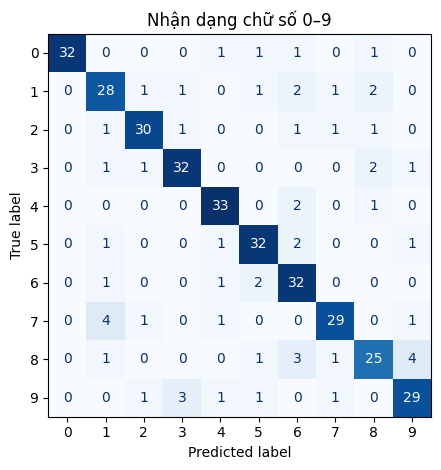

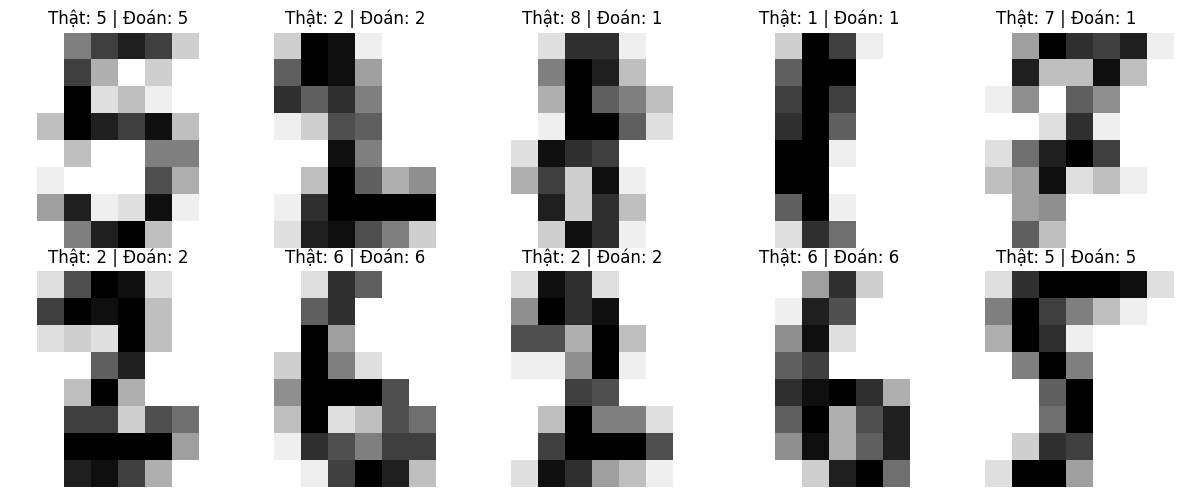

Downloading...
From: https://drive.google.com/uc?id=1KU83z5OU2j69YBPI7uMPcLPSUxidd6Ia
To: /content/test_image_Bai7_01.jpg
100%|██████████| 52.0k/52.0k [00:00<00:00, 38.9MB/s]
Downloading...
From: https://drive.google.com/uc?id=1BH2qwN62GKZIHcF0kUi0N13YG2eex3wx
To: /content/test_image_Bai7_02.jpg
100%|██████████| 43.9k/43.9k [00:00<00:00, 12.6MB/s]


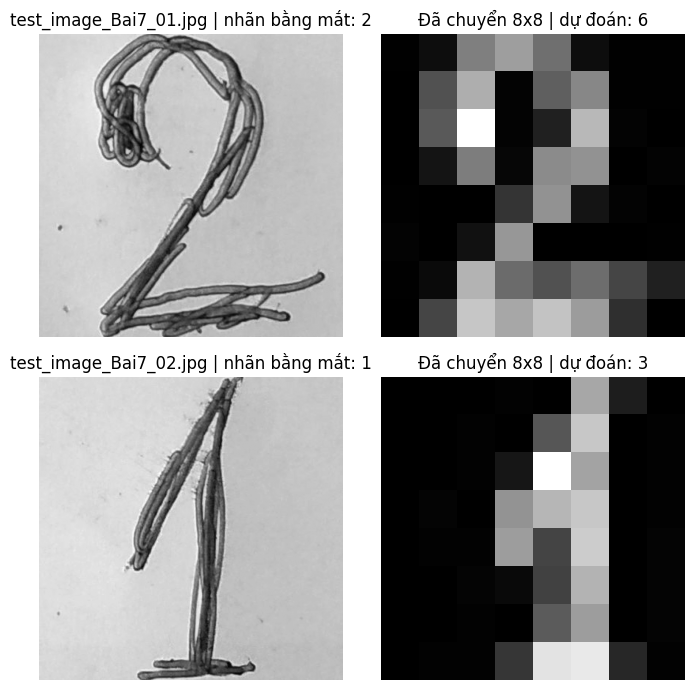

KẾT QUẢ KIỂM THỬ 2 ẢNH THỰC TẾ:
                   Ảnh  Nhãn quan sát  Nhãn dự đoán  Khớp
test_image_Bai7_01.jpg              2             6 False
test_image_Bai7_02.jpg              1             3 False
Số ảnh nhận dạng đúng: 0 / 2


In [1]:
print("Họ tên: Nguyễn Đức Vinh | MSSV: 6451071087")
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, accuracy_score, precision_score,
                             recall_score, f1_score, classification_report)

# Khi chạy trên Colab, nếu chưa có file trong thư mục hiện tại, tự tải từ Drive công khai.
DATA_DIR = Path('data') if Path('data').exists() else Path('.')
DRIVE_IDS = {
    'adult.data.csv': '1BYKP73pyzphA5YHR1fVvn2A0kBpr09TB',
    'adult.test.csv': '1Vh7e1IBL0SRxjT3gU_v_rnIcAT18griD',
    'winequality-red.csv': '1rzLiUi64RLmMV8ApudCt6aJyv_OkhADH',
    'heart.csv': '10N9jGzMn-MagDWXORdP-qIpwC3omZJHb',
    'mushrooms.csv': '11OXFpnwUwK_Ka9BFmboMoT9RhTRe3CFW',
    'test_image_Bai7_01.jpg': '1KU83z5OU2j69YBPI7uMPcLPSUxidd6Ia',
    'test_image_Bai7_02.jpg': '1BH2qwN62GKZIHcF0kUi0N13YG2eex3wx'
}
def get_file(filename):
    p = DATA_DIR / filename
    if not p.exists():
        import subprocess, sys
        try:
            import gdown
        except ImportError:
            subprocess.check_call([sys.executable, '-m', 'pip', '-q', 'install', 'gdown'])
            import gdown
        gdown.download(id=DRIVE_IDS[filename], output=str(p), quiet=False)
    if not p.exists():
        raise FileNotFoundError('Không tải được ' + filename + '. Hãy tải từ Drive và upload lên Colab.')
    return p

DATASET = 'digits'

from sklearn.datasets import load_digits
from PIL import Image, ImageOps
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, accuracy_score
DIGITS = load_digits()
X = DIGITS.data                  # 1797 ảnh 8x8, mỗi ảnh 64 đặc trưng
y = DIGITS.target
print('Dữ liệu sklearn digits (8x8):', X.shape, 'Nhãn:', np.unique(y))
fig, axes = plt.subplots(1, 4, figsize=(10, 3))
for i, ax in enumerate(axes):
    j = np.where(y==i)[0][0]
    ax.imshow(DIGITS.images[j], cmap='gray_r'); ax.set_title(f'Nhãn {i}'); ax.axis('off')
plt.tight_layout(); plt.show()
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
model = DecisionTreeClassifier(criterion='entropy', random_state=42)
model.fit(X_train,y_train)
pred=model.predict(X_test)
print('Accuracy của cây ID3 theo entropy:',round(accuracy_score(y_test,pred),4))
print(classification_report(y_test,pred,zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test,pred,cmap='Blues',colorbar=False)
plt.title('Nhận dạng chữ số 0–9'); plt.tight_layout(); plt.show()
fig, axes=plt.subplots(2,5,figsize=(12,5))
for i,ax in enumerate(axes.ravel()):
    ax.imshow(X_test[i].reshape(8,8),cmap='gray_r')
    ax.set_title(f'Thật: {y_test[i]} | Đoán: {pred[i]}');ax.axis('off')
plt.tight_layout();plt.show()
# Đọc và dự đoán TẤT CẢ ảnh kiểm thử: hai ảnh trùng tên gốc đã được đổi tên riêng.
TEST_IMAGES = [
    ('test_image_Bai7_01.jpg', 2),
    ('test_image_Bai7_02.jpg', 1),
]

def preprocess_handwritten_image(path, threshold=110):
    """Đưa ảnh chữ số thực tế thành vector (1, 64), thang xám 0..16."""
    gray = ImageOps.grayscale(Image.open(path).convert('RGB'))
    a = np.asarray(gray)
    edges = np.concatenate([a[0], a[-1], a[:, 0], a[:, -1]])
    foreground = np.asarray(ImageOps.invert(gray) if edges.mean() > 127 else gray)
    foreground = np.where(foreground > threshold, foreground, 0).astype(np.uint8)
    ys, xs = np.where(foreground > 0)
    if len(xs):
        crop = Image.fromarray(foreground[ys.min():ys.max()+1, xs.min():xs.max()+1])
    else:
        crop = Image.fromarray(foreground)
    w, h = crop.size
    canvas = Image.new('L', (max(w, h)+8, max(w, h)+8), 0)
    canvas.paste(crop, ((canvas.width-w)//2, (canvas.height-h)//2))
    small = canvas.resize((8, 8), Image.Resampling.LANCZOS)
    vector = np.asarray(small, dtype=float) / 255.0 * 16.0
    return gray, vector

records = []
fig, axes = plt.subplots(len(TEST_IMAGES), 2, figsize=(7, 7))
for idx, (filename, true_label) in enumerate(TEST_IMAGES):
    image_path = get_file(filename)
    original, pixels = preprocess_handwritten_image(image_path)
    prediction = int(model.predict(pixels.reshape(1, 64))[0])
    records.append({'Ảnh': filename, 'Nhãn quan sát': true_label,
                    'Nhãn dự đoán': prediction, 'Khớp': prediction == true_label})
    axes[idx, 0].imshow(original, cmap='gray')
    axes[idx, 0].set_title(f'{filename} | nhãn bằng mắt: {true_label}')
    axes[idx, 1].imshow(pixels, cmap='gray')
    axes[idx, 1].set_title(f'Đã chuyển 8x8 | dự đoán: {prediction}')
    for ax in axes[idx]: ax.axis('off')
plt.tight_layout()
plt.show()
print('KẾT QUẢ KIỂM THỬ 2 ẢNH THỰC TẾ:')
print(pd.DataFrame(records).to_string(index=False))
print('Số ảnh nhận dạng đúng:', sum(r['Khớp'] for r in records), '/', len(records))
